# Link:
`https://github.com/HuifangXiang711/CSE830/blob/main/Q6_report_updated.ipynb`

# 1. Hypothesis
Building upon the results from Q5, which demonstrated that Insertion Sort is more efficient for small input sizes (`n`), this experiment aims to create a hybrid sorting algorithm. **This algorithm will use Merge Sort as its primary strategy for dividing the problem, but will switch to Insertion Sort for partitions smaller than or equal to a specific threshold, `k`.**

My hypotheses:

The resulting hybrid algorithm will be faster than a pure Merge Sort implementation across a wide range of input sizes. This is because the hybrid approach will avoid the relatively high overhead of Merge Sort's deep recursion on very small arrays, leveraging Insertion Sort's low-overhead performance in those specific cases.

The optimal value for the threshold `k` will be related to the crossover point found in Q5 ($n ≈ 63.3$), but likely not identical. I suspect the optimal `k` might be smaller than the crossover point. The reasoning is that the optimal cutoff balances the cost of
Insertion Sort on all leaf partitions against the cost of the remaining merge
levels. This differs from comparing two standalone sorts in Q5. A smaller k
means more recursive splitting before switching to Insertion Sort.


# 2. Methods
The experiment has two phases: finding a good threshold k, then comparing
the hybrid algorithm against Insertion Sort and Merge Sort.

The sorting functions below are unchanged. The hybrid algorithm calls
Insertion Sort when a partition's length is at most k and otherwise splits
and merges recursively. This is the assignment's merge/insertion hybrid;
it does not implement all features of Python's production Timsort.

Run all cells in order using Python 3 with NumPy and Matplotlib. The code
prints the Python version, NumPy version, and platform. Python is interpreted;
there is no separate compilation step or optimization flag. All random input
lists contain integers drawn uniformly from 0 through 499, matching Q5.
The code and repository reference are provided above.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import timeit
import sys
import platform

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"Platform: {platform.platform()}")
plt.style.use('seaborn-v0_8-whitegrid')

sys.setrecursionlimit(2000)

# --- Reuse my functions from Q5 ---
def insertion_sort(arr):
    """Sorts an array in place using the insertion sort algorithm."""
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        while j >= 0 and key < arr[j]:
            arr[j + 1] = arr[j]
            j -= 1
        arr[j + 1] = key
    return arr

def merge_sort(arr):
    """Sorts an array using the merge sort algorithm."""
    if len(arr) > 1:
        mid = len(arr) // 2
        left_half = arr[:mid]
        right_half = arr[mid:]

        merge_sort(left_half)
        merge_sort(right_half)

        i = j = k = 0
        while i < len(left_half) and j < len(right_half):
            if left_half[i] < right_half[j]:
                arr[k] = left_half[i]
                i += 1
            else:
                arr[k] = right_half[j]
                j += 1
            k += 1

        while i < len(left_half):
            arr[k] = left_half[i]
            i += 1
            k += 1

        while j < len(right_half):
            arr[k] = right_half[j]
            j += 1
            k += 1
    return arr

# --- Q6: New Hybrid Sort Implementation ---
def hybrid_sort_recursive(arr, k):
    """
    Recursive helper for hybrid sort.
    Sorts an array using merge sort, but switches to insertion sort
    for partitions of size <= k.
    """
    if len(arr) <= k:
        insertion_sort(arr)
    elif len(arr) > 1:
        mid = len(arr) // 2
        left_half = arr[:mid]
        right_half = arr[mid:]

        hybrid_sort_recursive(left_half, k)
        hybrid_sort_recursive(right_half, k)

        i = j = l = 0 
        while i < len(left_half) and j < len(right_half):
            if left_half[i] < right_half[j]:
                arr[l] = left_half[i]
                i += 1
            else:
                arr[l] = right_half[j]
                j += 1
            l += 1

        while i < len(left_half):
            arr[l] = left_half[i]
            i += 1
            l += 1

        while j < len(right_half):
            arr[l] = right_half[j]
            j += 1
            l += 1
    return arr

def hybrid_sort(arr, k):
    return hybrid_sort_recursive(arr, k)

Python: 3.9.6
NumPy: 2.0.2
Platform: macOS-26.6.2-arm64-arm-64bit


## Experiment 1: Finding the Optimal k
1. Test n = 5000 and n = 10000, with k = 1 and every even value from 2 to 128.
   This range covers thresholds well below and above the Q5 crossover.
2. Use seed 42. For each n, time five batches of ten independently generated
   random lists. Within each batch, all k values receive copies of the same
   lists. Shuffle the order of k values in each batch to reduce order effects.
3. Generate inputs before timing. Use `timeit.timeit` to measure each batch,
   divide by ten, and report the median of five batch means. Copying and the
   loop overhead are included; random generation is excluded.
4. Report the best measured k for each n. Select a single tested k for phase 2
   by minimizing the mean normalized time across the two n values: for each n,
   divide each candidate's time by the best time observed for that n, then
   average these two ratios. Thus each tested size receives equal weight.
   This selects a tested candidate rather than averaging two cutoff values.


Starting Experiment 1: Finding the optimal k...
Testing for array size n = 5000...
Testing for array size n = 10000...
Experiment 1 complete.
For n=5000, best measured k is 10 with time 0.004954s
For n=10000, best measured k is 14 with time 0.010984s
Chosen tested k for next experiment: k = 16


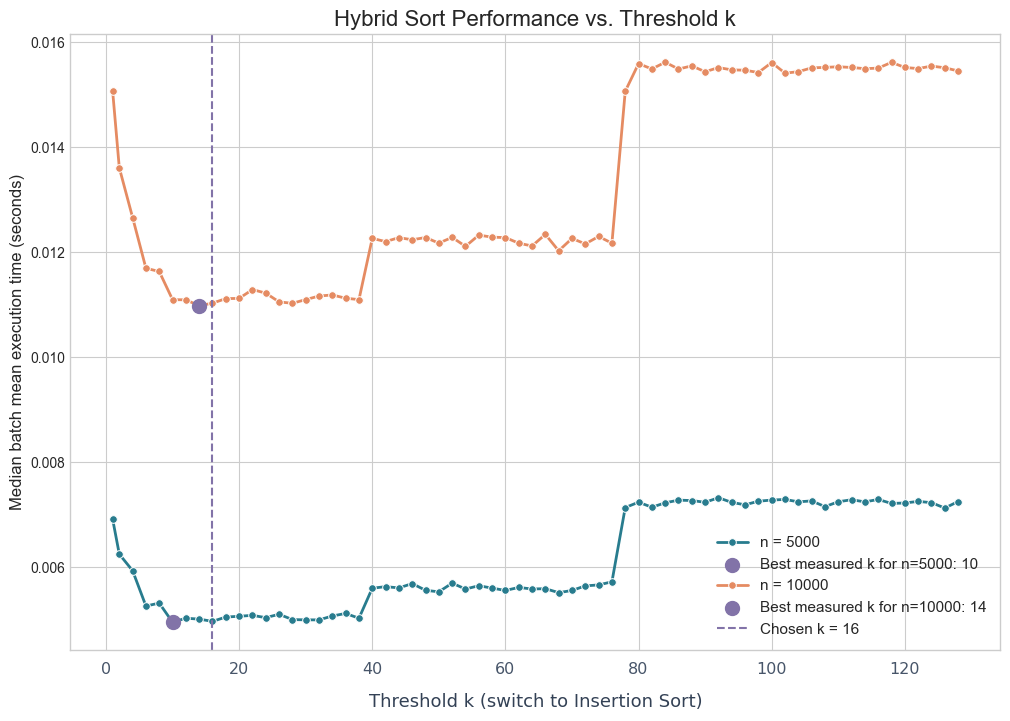

In [2]:
print("Starting Experiment 1: Finding the optimal k...")

test_n_values = [5000, 10000]
k_values = np.unique(np.concatenate(([1], np.arange(2, 129, 2))))
k_timing_results = {n: [] for n in test_n_values}
num_repeats_k_search = 50
num_batches = 5
runs_per_batch = num_repeats_k_search // num_batches
rng = np.random.default_rng(42)

for n in test_n_values:
    print(f"Testing for array size n = {n}...")
    batch_times = {int(k): [] for k in k_values}
    for batch in range(num_batches):
        datasets = [rng.integers(0, 500, n).tolist()
                    for _ in range(runs_per_batch)]
        for k in rng.permutation(k_values):
            def one_batch():
                for data in datasets:
                    hybrid_sort(data.copy(), int(k))
            elapsed = timeit.timeit(one_batch, number=1)
            batch_times[int(k)].append(elapsed / runs_per_batch)
    k_timing_results[n] = [float(np.median(batch_times[int(k)])) for k in k_values]

print("Experiment 1 complete.")

fig, ax = plt.subplots(figsize=(12, 8))
optimal_k_values = []
for n, color in zip(test_n_values, ['#287C8E', '#E58B62']):
    times = k_timing_results[n]
    ax.plot(k_values, times, 'o-', label=f'n = {n}', color=color,
            linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)
    min_time = min(times)
    optimal_k = int(k_values[times.index(min_time)])
    optimal_k_values.append(optimal_k)
    print(f"For n={n}, best measured k is {optimal_k} with time {min_time:.6f}s")
    ax.scatter([optimal_k], [min_time], color='#8273A8', s=100, zorder=5,
               label=f'Best measured k for n={n}: {optimal_k}')

time_matrix = np.array([k_timing_results[n] for n in test_n_values])
normalized_scores = (time_matrix / time_matrix.min(axis=1, keepdims=True)).mean(axis=0)
k_optimal = int(k_values[np.argmin(normalized_scores)])
print(f"Chosen tested k for next experiment: k = {k_optimal}")
ax.axvline(k_optimal, color='#8273A8', linestyle='--', label=f'Chosen k = {k_optimal}')

ax.set_title('Hybrid Sort Performance vs. Threshold k', fontsize=16)
ax.set_xlabel('Threshold k (switch to Insertion Sort)', fontsize=13,
              fontfamily='DejaVu Sans', fontweight='medium', color='#334155', labelpad=12)
ax.tick_params(axis='x', labelsize=11.5, labelcolor='#475569', pad=8)
for label in ax.get_xticklabels():
    label.set_fontfamily('DejaVu Sans')
ax.set_ylabel('Median batch mean execution time (seconds)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True)
plt.show()


# 3. Results
## Results 1
For n = 5000, the best measured candidate was **k = 16**; for n = 10000,
it was **k = 30**. The normalized-time criterion selected **k = 16**
for the final comparison. This is the best measured candidate under the stated
criterion, rather than a proven unique optimum.

At both search sizes, the tested thresholds **10, 12, 14, 16, and 18**
produce the same leaf partitions as k = 16. Differences within this plateau
are timing variation, not changes in the algorithm. The first graph also
shows that very small and large thresholds are slower than the intermediate
thresholds for these inputs.


## Experiment 2: Final Performance Comparison
Use the single tested threshold selected in Experiment 1.

Test the Q5 sizes (2, 4, ..., 48; 50, 60, ..., 200; 250, 300, ..., 500),
and add n = 1000, 2000, 5000, and 10000 to check larger inputs.
Use a separate random generator with seed 43. At each size, prepare identical
random inputs for all three algorithms and sort a fresh copy on every run.
Time 500 sorts per algorithm for n <= 500, and five sorts for larger n to
limit the cost of quadratic Insertion Sort. Divide each batch duration by its
number of sorts. Rotate algorithm timing order at successive sizes.
Random generation is excluded; copying and batch-loop overhead are included.
These single-batch means do not provide confidence intervals.


Starting Experiment 2: Comparing all three algorithms using k=16...
Experiment 2 complete.


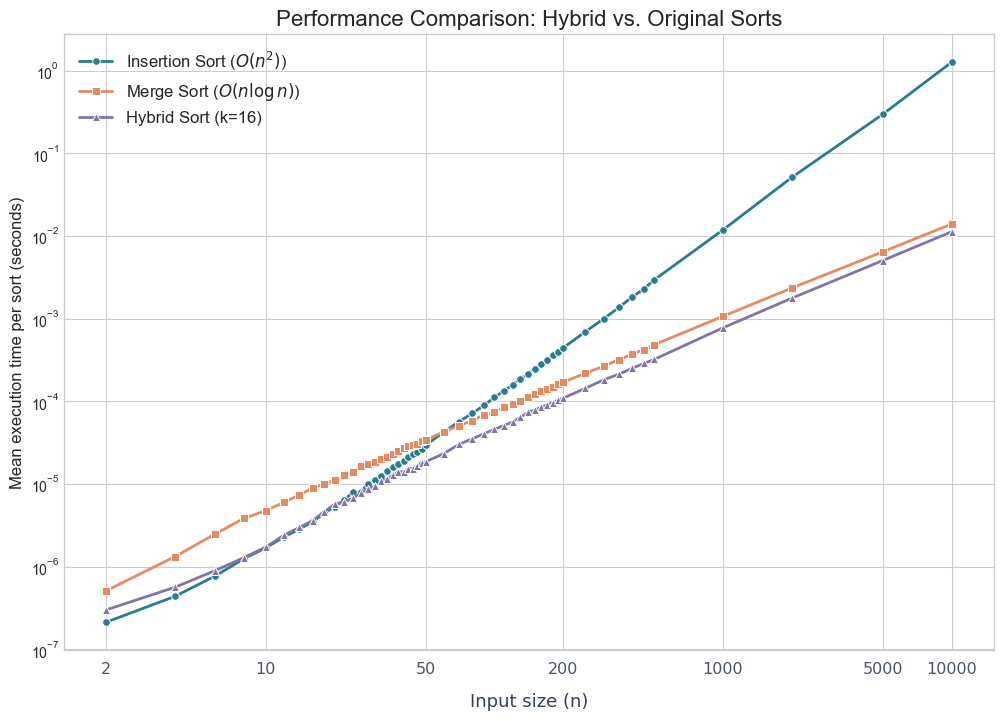

In [3]:
print(f"Starting Experiment 2: Comparing all three algorithms using k={k_optimal}...")

n_values_small = np.arange(2, 50, 2)
n_values_medium = np.arange(50, 201, 10)
n_values_large = np.arange(200, 501, 50)
n_values = np.unique(np.concatenate([n_values_small, n_values_medium,
                                     n_values_large, [1000, 2000, 5000, 10000]]))
insertion_times_final = []
merge_times_final = []
hybrid_times_final = []
num_repeats_final = 500
rng_final = np.random.default_rng(43)

for index, n in enumerate(n_values):
    repeats = num_repeats_final if n <= 500 else 5
    datasets = [rng_final.integers(0, 500, int(n)).tolist() for _ in range(repeats)]
    algorithms = [insertion_sort, merge_sort, lambda arr: hybrid_sort(arr, k_optimal)]
    times = [None] * 3
    for j in np.roll(np.arange(3), index % 3):
        def one_batch():
            for data in datasets:
                algorithms[j](data.copy())
        times[j] = timeit.timeit(one_batch, number=1) / repeats
    insertion_times_final.append(times[0])
    merge_times_final.append(times[1])
    hybrid_times_final.append(times[2])

print("Experiment 2 complete.")
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(n_values, insertion_times_final, 'o-', label='Insertion Sort ($O(n^2)$)',
        color='#287C8E', linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)
ax.plot(n_values, merge_times_final, 's-', label=r'Merge Sort ($O(n \log n)$)',
        color='#E58B62', linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)
ax.plot(n_values, hybrid_times_final, '^-', label=f'Hybrid Sort (k={k_optimal})',
        color='#8273A8', linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)
ax.set_title('Performance Comparison: Hybrid vs. Original Sorts', fontsize=16)
ax.set_xlabel('Input size (n)', fontsize=13, fontfamily='DejaVu Sans',
              fontweight='medium', color='#334155', labelpad=12)
ax.set_ylabel('Mean execution time per sort (seconds)', fontsize=12)
ax.legend(fontsize=12)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xticks([2, 10, 50, 200, 1000, 5000, 10000])
ax.set_xticklabels(['2', '10', '50', '200', '1000', '5000', '10000'],
                   fontfamily='DejaVu Sans', fontsize=11.5, color='#475569')
ax.tick_params(axis='x', which='major', pad=8)
ax.grid(True)
plt.show()


## Results 2
The graph compares Insertion Sort (blue-green), Merge Sort (warm orange), and
Hybrid Sort (purple, k = 16). For n <= 16, the hybrid calls Insertion Sort
directly. The two curves are close at these small sizes; measured times can
still differ because of wrapper overhead and timing variation.

At the four larger tested sizes (n = 1000, 2000, 5000, 10000), the hybrid's
measured time is lower than Merge Sort's, while Insertion Sort becomes much
slower as n increases. These results support the hybrid's large-input advantage
under the tested conditions. Small differences between nearby curves should
not be interpreted as statistically distinguishable from one timing batch.


# 4. Discussion
The chosen cutoff k = 16 is below the Q5 crossover interval of
**n = 60-70** (estimate n ≈ 63.3). The cutoff and crossover need
not coincide. Q5 compares Insertion Sort with a full pure Merge Sort on a
standalone list. Q6 compares insertion at a leaf with further recursion whose
children will themselves use the hybrid. The alternatives therefore differ.

Increasing k creates larger insertion-sorted leaves and removes merge levels;
decreasing k creates smaller leaves and retains more merge levels. The best
tradeoff depends on both costs. Balanced recursive splits also mean that a
range of thresholds can produce identical partitions. An exact best measured
k within that range is affected by noise, and different n values can produce
different partition sizes and preferred thresholds.

The best measured candidates differ between n = 5000 (k = 16) and
n = 10000 (k = 30). This suggests that one exact cutoff should not be treated
as universally optimal; partition structure and timing variation both matter.

The plateau was an important measurement challenge: more repetitions do not
make identical recursion structures distinct. Paired inputs, randomized search
order, and five timing batches reduce measurement bias, but do not establish
a unique optimum or a universal advantage over both original algorithms.


# 5. Conclusions
For these implementations and random integer inputs, **k = 16** was the
best measured common cutoff among the tested candidates under the normalized
timing criterion for n = 5000 and n = 10000. The tested values 10, 12, 14,
16, and 18 produce equivalent partitions at both search sizes, so the
experiment does not establish a unique optimal integer.

With k = 16, Hybrid Sort was faster than pure Merge Sort at the four larger
comparison sizes (n = 1000, 2000, 5000, 10000). At small sizes, its performance
is close to Insertion Sort's. The hybrid cutoff is a separate optimization
from Q5's standalone crossover; neither value should be treated as universal.
